In [5]:
# FORCE GPU
device = torch.device("cuda")
print("Using GPU:", torch.cuda.get_device_name(0))

Using GPU: Tesla T4


Using GPU: Tesla T4
Epoch 1 Train MAE: 38.9235
Epoch 2 Train MAE: 33.3814
Epoch 3 Train MAE: 30.7845
Epoch 4 Train MAE: 28.1849
Epoch 5 Train MAE: 26.8577
Validation MAE: 27.851835
Bucket Accuracy: 0.22780126849894292


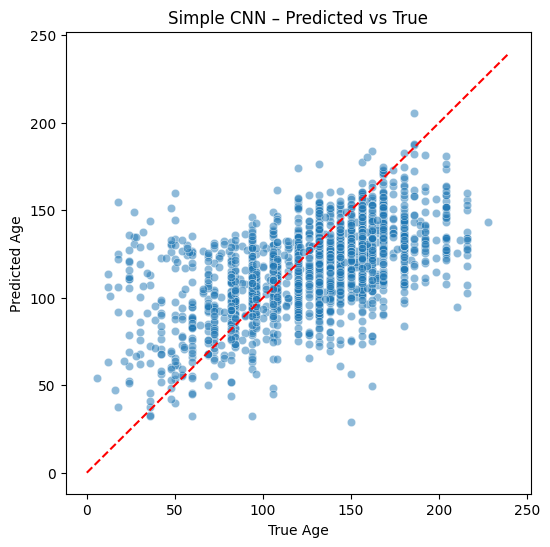

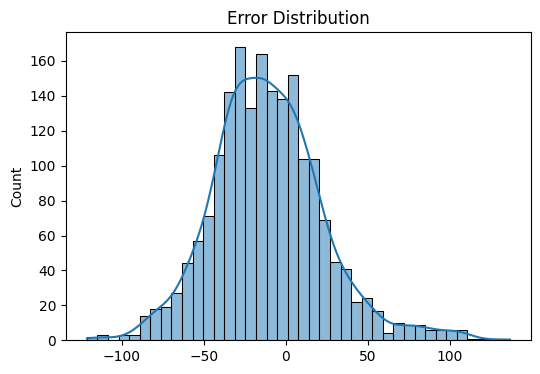

In [6]:
# ============================================================
# BASIC CNN BASELINE (GPU ENABLED) FOR RSNA BONE AGE
# ============================================================

import os, cv2, torch
import numpy as np, pandas as pd
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import torchvision.transforms as T
import matplotlib.pyplot as plt
import seaborn as sns

# FORCE GPU
device = torch.device("cuda")
print("Using GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv("/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset.csv")
df["gender"] = df["male"].astype(int)

train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["gender"]
)

# ============================================================
# 2. DATASET
# ============================================================

transform = T.Compose([
    T.ToPILImage(),
    T.Resize((128,128)),
    T.ToTensor()
])

class BoneAgeSimple(Dataset):
    def __init__(self, df, img_dir):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        img = transform(img)
        target = torch.tensor(row["boneage"], dtype=torch.float32)

        return img, target

train_dataset = BoneAgeSimple(train_df, "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset/boneage-training-dataset")
val_dataset   = BoneAgeSimple(val_df,   "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset/boneage-training-dataset")

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False)

# ============================================================
# 3. BASIC CNN MODEL (GPU)
# ============================================================

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Linear(64*16*16, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x).squeeze(1)

model = SimpleCNN().to(device)
criterion = nn.L1Loss()  # MAE
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# ============================================================
# 4. TRAINING LOOP (GPU)
# ============================================================

for epoch in range(5):
    model.train()
    total_loss = 0
    for img, target in train_loader:
        img = img.to(device)
        target = target.to(device)

        pred = model(img)
        loss = criterion(pred, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Train MAE: {total_loss/len(train_loader):.4f}")

# ============================================================
# 5. VALIDATION — MAE + ACCURACY
# ============================================================

model.eval()
preds, targets = [], []

with torch.no_grad():
    for img, target in val_loader:
        img = img.to(device)
        pred = model(img).cpu().numpy()
        preds.extend(pred)
        targets.extend(target.numpy())

preds = np.array(preds)
targets = np.array(targets)

# MAE
mae = np.mean(np.abs(preds - targets))
print("Validation MAE:", mae)

# ============================================================
# 6. AGE BUCKET ACCURACY
# ============================================================

def bucketize(x):
    return (x // 20).astype(int)

true_buckets = bucketize(targets)
pred_buckets = bucketize(preds)

accuracy = np.mean(true_buckets == pred_buckets)
print("Bucket Accuracy:", accuracy)

# ============================================================
# 7. VISUALIZATION
# ============================================================

plt.figure(figsize=(6,6))
sns.scatterplot(x=targets, y=preds, alpha=0.5)
plt.plot([0,240],[0,240],'r--')
plt.xlabel("True Age")
plt.ylabel("Predicted Age")
plt.title("Simple CNN – Predicted vs True")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(preds - targets, bins=40, kde=True)
plt.title("Error Distribution")
plt.show()


In [ ]:
# ============================================================
# REGION-BASED BONE AGE MODELS WITH GENDER (ConvNeXtV2)
# ============================================================

import os, cv2, torch
import numpy as np, pandas as pd
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ============================================================
# 1. CONFIG
# ============================================================

CSV_PATH = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset.csv"
IMG_DIR  = "/kaggle/input/datasets/kmader/rsna-bone-age/boneage-training-dataset/boneage-training-dataset"

# Assume registered images ~2080x1600 (H x W)
# You can tweak these crops if your resolution differs.

REGION_CROPS = {
    "whole":   (40, 40, 2000, 1500),   # (y, x, h, w)
    "carpal":  (1100, 450, 750, 750),
    "meta":    (600, 500, 600, 1400)
}

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5
LR = 1e-4

# ============================================================
# 2. DATAFRAME + SPLIT
# ============================================================

df = pd.read_csv(CSV_PATH)
df["gender"] = df["male"].astype(int)  # 0/1

train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["gender"]
)

print("Train:", len(train_df), "Val:", len(val_df))

# ============================================================
# 3. TRANSFORMS
# ============================================================

base_transform = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# ============================================================
# 4. DATASET WITH REGION CROPPING + GENDER
# ============================================================

class BoneAgeRegionDataset(Dataset):
    def __init__(self, df, img_dir, region_name, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.region_name = region_name
        self.transform = transform
        self.crop = REGION_CROPS[region_name]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{row['id']}.png")

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        y, x, h, w = self.crop
        img = img[y:y+h, x:x+w]

        if self.transform:
            img = self.transform(img)

        target = torch.tensor(row["boneage"], dtype=torch.float32)
        gender = torch.tensor(row["gender"], dtype=torch.long)

        return img, gender, target

# ============================================================
# 5. MODEL: ConvNeXtV2 + GENDER EMBEDDING
# ============================================================

class ConvNeXtV2Gender(nn.Module):
    def __init__(self, backbone_name="convnextv2_tiny.fcmae_ft_in22k_in1k"):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=True)
        in_features = self.backbone.num_features
        self.backbone.reset_classifier(0)

        self.gender_embed = nn.Embedding(2, 16)
        self.fc = nn.Linear(in_features + 16, 1)

    def forward(self, x, gender):
        f = self.backbone(x)
        g = self.gender_embed(gender)
        out = torch.cat([f, g], dim=1)
        return self.fc(out).squeeze(1)

# ============================================================
# 6. TRAIN + EVAL HELPERS
# ============================================================

def train_one_region(region_name, train_df, val_df):
    print(f"\n========== REGION: {region_name.upper()} ==========")

    train_ds = BoneAgeRegionDataset(train_df, IMG_DIR, region_name, base_transform)
    val_ds   = BoneAgeRegionDataset(val_df,   IMG_DIR, region_name, base_transform)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)

    model = ConvNeXtV2Gender().to(device)
    criterion = nn.L1Loss()
    optimizer = optim.Adam(model.parameters(), lr=LR)

    # ---- TRAIN ----
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        for img, gender, target in train_loader:
            img = img.to(device)
            gender = gender.to(device)
            target = target.to(device)

            pred = model(img, gender)
            loss = criterion(pred, target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{EPOCHS} [{region_name}] Train MAE: {total_loss/len(train_loader):.4f}")

    # ---- VALIDATION ----
    model.eval()
    preds, targets, genders = [], [], []

    with torch.no_grad():
        for img, gender, target in val_loader:
            img = img.to(device)
            gender = gender.to(device)

            pred = model(img, gender).cpu().numpy()
            preds.extend(pred)
            targets.extend(target.numpy())
            genders.extend(gender.cpu().numpy())

    preds = np.array(preds)
    targets = np.array(targets)
    genders = np.array(genders)

    overall_mae = np.mean(np.abs(preds - targets))
    print(f"[{region_name}] Overall Val MAE: {overall_mae:.4f}")

    # MAE by gender
    mae_male = np.mean(np.abs(preds[genders==1] - targets[genders==1])) if np.any(genders==1) else None
    mae_fem  = np.mean(np.abs(preds[genders==0] - targets[genders==0])) if np.any(genders==0) else None

    print(f"[{region_name}] Male MAE:   {mae_male:.4f}" if mae_male is not None else f"[{region_name}] Male MAE: N/A")
    print(f"[{region_name}] Female MAE: {mae_fem:.4f}" if mae_fem is not None else f"[{region_name}] Female MAE: N/A")

    return {
        "region": region_name,
        "overall_mae": overall_mae,
        "male_mae": mae_male,
        "female_mae": mae_fem,
        "preds": preds,
        "targets": targets,
        "genders": genders
    }

# ============================================================
# 7. RUN ALL THREE REGIONS
# ============================================================

results = []
for region in ["whole", "carpal", "meta"]:
    res = train_one_region(region, train_df, val_df)
    results.append(res)

# ============================================================
# 8. SUMMARY TABLE
# ============================================================

summary = pd.DataFrame([
    {
        "Region": r["region"],
        "Overall_MAE": r["overall_mae"],
        "Male_MAE": r["male_mae"],
        "Female_MAE": r["female_mae"]
    }
    for r in results
])

print("\n=== REGION PERFORMANCE SUMMARY ===")
print(summary)

# ============================================================
# 9. OPTIONAL: PLOT ONE REGION'S PREDICTIONS
# ============================================================

best_region = min(results, key=lambda x: x["overall_mae"])
print("\nBest region:", best_region["region"], "MAE:", best_region["overall_mae"])

preds = best_region["preds"]
targets = best_region["targets"]

plt.figure(figsize=(6,6))
sns.scatterplot(x=targets, y=preds, alpha=0.5)
plt.plot([0,240],[0,240],'r--')
plt.xlabel("True Age (months)")
plt.ylabel("Predicted Age (months)")
plt.title(f"Predicted vs True – {best_region['region']}")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(preds - targets, bins=40, kde=True)
plt.xlabel("Error (months)")
plt.title(f"Error Distribution – {best_region['region']}")
plt.show()


Using: cuda
Train: 10719 Val: 1892

========== REGION: WHOLE ==========


model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

Epoch 1/5 [whole] Train MAE: 96.3947
Epoch 2/5 [whole] Train MAE: 65.0710
Epoch 3/5 [whole] Train MAE: 43.6728
Epoch 4/5 [whole] Train MAE: 34.6863
Epoch 5/5 [whole] Train MAE: 33.0583
[whole] Overall Val MAE: 32.5385
[whole] Male MAE:   34.5927
[whole] Female MAE: 30.1099

========== REGION: CARPAL ==========
